# Customer Segmentation — PCA, K-Means and Business Personas

**DecodeLabs Data Science Internship · Project 3**

Discover hidden customer groups in unlabeled retail data and translate them into actionable
business personas.

**Pipeline:** Scale → Compress (PCA) → Cluster (K-Means) → Translate (Personas)

**Dataset:** [Customer Personality Analysis](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis) — 2,240 customers, 29 columns.

## 1. Setup

In [92]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "raw" / "marketing_campaign.csv"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
print("Data file found:", DATA_PATH.exists())

Data file found: True


## 2. Load the data

The separator is detected automatically. The raw file is read only and never modified.

In [93]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"{DATA_PATH} not found - see data/raw/README.md")

raw = pd.read_csv(DATA_PATH, sep=None, engine="python")
print(f"Customers: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
raw.head()

Customers: 2,240 | Columns: 29


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


### 2.1 Column overview

In [94]:
pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "unique_values": raw.nunique(),
})

,dtype,non_null,missing,unique_values
ID,int64,2240,0,2240
Year_Birth,int64,2240,0,59
Education,str,2240,0,5
Marital_Status,str,2240,0,8
Income,float64,2216,24,1974
Kidhome,int64,2240,0,3
Teenhome,int64,2240,0,3
Dt_Customer,str,2240,0,663
Recency,int64,2240,0,100
MntWines,int64,2240,0,776


## 3. Data-quality checks

### 3.1 Missing values

In [95]:
missing = raw.isna().sum()
missing = missing[missing > 0]
pd.DataFrame({"missing": missing, "percent": (missing / len(raw) * 100).round(2)})

,missing,percent
Income,24,1.07


### 3.2 Duplicates

Rows that are identical in every column except `ID` represent the same customer recorded twice.

In [96]:
print("Exact duplicate rows:          ", int(raw.duplicated().sum()))
print("Duplicates ignoring ID:        ", int(raw.drop(columns="ID").duplicated().sum()))
print("Duplicate customer IDs:        ", int(raw["ID"].duplicated().sum()))

Exact duplicate rows:           0
Duplicates ignoring ID:         182
Duplicate customer IDs:         0


### 3.3 Constant columns

In [97]:
constant_cols = [c for c in raw.columns if raw[c].nunique(dropna=False) == 1]
pd.DataFrame({"only value": raw[constant_cols].iloc[0]})

,only value
Z_CostContact,3
Z_Revenue,11


### 3.4 Categorical columns

In [98]:
for col in ["Education", "Marital_Status"]:
    print(f"{col}:\n{raw[col].value_counts().to_string()}\n")
print("Dt_Customer example values:", raw["Dt_Customer"].head(3).tolist())

Education:
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54

Marital_Status:
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2

Dt_Customer example values: ['04-09-2012', '08-03-2014', '21-08-2013']


### 3.5 Numeric ranges

In [99]:
numeric = raw.select_dtypes(include="number")
summary = numeric.describe().T
summary["skew"] = numeric.skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
ID,2240.0,5592.16,3246.66,0.0,2828.25,5458.5,8427.75,11191.0,0.04
Year_Birth,2240.0,1968.81,11.98,1893.0,1959.00,1970.0,1977.00,1996.0,-0.35
Income,2216.0,52247.25,25173.08,1730.0,35303.00,51381.5,68522.00,666666.0,6.76
Kidhome,2240.0,0.44,0.54,0.0,0.00,0.0,1.00,2.0,0.64
Teenhome,2240.0,0.51,0.54,0.0,0.00,0.0,1.00,2.0,0.41
Recency,2240.0,49.11,28.96,0.0,24.00,49.0,74.00,99.0,-0.00
MntWines,2240.0,303.94,336.60,0.0,23.75,173.5,504.25,1493.0,1.18
MntFruits,2240.0,26.30,39.77,0.0,1.00,8.0,33.00,199.0,2.10
MntMeatProducts,2240.0,166.95,225.72,0.0,16.00,67.0,232.00,1725.0,2.08
MntFishProducts,2240.0,37.53,54.63,0.0,3.00,12.0,50.00,259.0,1.92


### 3.6 Extreme values in birth year and income

In [100]:
for col in ["Year_Birth", "Income"]:
    values = raw[col].dropna().sort_values()
    print(f"{col:<10} lowest  {values.head(5).tolist()}")
    print(f"{'':<10} highest {values.tail(5).tolist()}\n")

Year_Birth lowest  [1893, 1899, 1900, 1940, 1941]
           highest [1995, 1995, 1995, 1996, 1996]

Income     lowest  [1730.0, 2447.0, 3502.0, 4023.0, 4428.0]
           highest [157243.0, 157733.0, 160803.0, 162397.0, 666666.0]



## 4. Data cleaning

| Issue found | Rule applied | Reason |
|---|---|---|
| `Z_CostContact`, `Z_Revenue` are constant | drop both columns | carry no information |
| `Marital_Status` labels `Alone`, `Absurd`, `YOLO` | `Alone` → `Single`; drop `Absurd`, `YOLO` | `Alone` means single; the others are not valid statuses |
| Rows identical except for `ID` | keep the first occurrence | one customer counted twice would bias a cluster |
| `Income` missing for 1.07% of customers | drop those rows | under 5% missing → drop rows |
| `Year_Birth` 1893, 1899, 1900 | drop ages above 100 | impossible ages |
| `Income` of 666,666 | drop incomes above Q3 + 3 × IQR | Tukey far-out fence for implausible values |

Labels are standardised **before** duplicates are removed, so two records that differ only by
`Alone` vs `Single` are recognised as the same customer.

Age and tenure are measured from the latest enrolment date in the data (`Dt_Customer`), because
the dataset does not state its collection date.

In [101]:
df = raw.copy()
log = [("raw data", len(df))]

df = df.drop(columns=constant_cols)

df["Marital_Status"] = df["Marital_Status"].replace({"Alone": "Single"})
df = df[~df["Marital_Status"].isin(["Absurd", "YOLO"])]
log.append(("invalid marital status removed", len(df)))

df = df[~df.drop(columns="ID").duplicated()]
log.append(("duplicates (ignoring ID) removed", len(df)))

df = df.dropna(subset=["Income"])
log.append(("missing income removed", len(df)))

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
REFERENCE_DATE = df["Dt_Customer"].max()
df["Age"] = REFERENCE_DATE.year - df["Year_Birth"]
df = df[df["Age"] <= 100]
log.append(("age over 100 removed", len(df)))

q1, q3 = df["Income"].quantile([0.25, 0.75])
income_fence = q3 + 3 * (q3 - q1)
df = df[df["Income"] <= income_fence]
log.append((f"income above {income_fence:,.0f} removed", len(df)))

df = df.reset_index(drop=True)
cleaning_log = pd.DataFrame(log, columns=["step", "customers left"])
cleaning_log["removed"] = (-cleaning_log["customers left"].diff()).fillna(0).astype(int)
print("Reference date:", REFERENCE_DATE.date())
cleaning_log

Reference date: 2014-06-29


,step,customers left,removed
0,raw data,2240,0
1,invalid marital status removed,2236,4
2,duplicates (ignoring ID) removed,2053,183
3,missing income removed,2029,24
4,age over 100 removed,2026,3
5,"income above 167,538 removed",2025,1


### 4.1 Validation after cleaning

In [102]:
pd.Series({
    "missing values": int(df.isna().sum().sum()),
    "duplicates (ignoring ID)": int(df.drop(columns="ID").duplicated().sum()),
    "age range": f"{df['Age'].min()} – {df['Age'].max()}",
    "income range": f"{df['Income'].min():,.0f} – {df['Income'].max():,.0f}",
    "marital status labels": sorted(df["Marital_Status"].unique()),
}, name="after cleaning").to_frame()

,after cleaning
missing values,0
duplicates (ignoring ID),0
age range,18 – 74
income range,"1,730 – 162,397"
marital status labels,"[Divorced, Married, Single, Together, Widow]"


## 5. Feature engineering

| Feature | Definition |
|---|---|
| `Age` | reference year − `Year_Birth` |
| `Tenure_Days` | days between enrolment and the reference date |
| `Living_With_Partner` | 1 if Married or Together, else 0 |
| `Education_Level` | Basic = 1, Graduation = 2, 2n Cycle / Master = 3, PhD = 4 |
| `Campaigns_Accepted` | accepted offers across the 5 campaigns and the last campaign (`Response`) |
| `Total_Spent` | sum of the six product spending columns |
| `Total_Purchases` | web + catalogue + store purchases |
| `Children` | `Kidhome` + `Teenhome` |

`2n Cycle` is the European second-cycle (Master's-level) degree.

In [103]:
mnt_cols = ["MntWines", "MntFruits", "MntMeatProducts",
            "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
campaign_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
                 "AcceptedCmp4", "AcceptedCmp5", "Response"]

df["Tenure_Days"] = (REFERENCE_DATE - df["Dt_Customer"]).dt.days
df["Living_With_Partner"] = df["Marital_Status"].isin(["Married", "Together"]).astype(int)
df["Education_Level"] = df["Education"].map(
    {"Basic": 1, "Graduation": 2, "2n Cycle": 3, "Master": 3, "PhD": 4})
df["Campaigns_Accepted"] = df[campaign_cols].sum(axis=1)
df["Total_Spent"] = df[mnt_cols].sum(axis=1)
df["Total_Purchases"] = df[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)
df["Children"] = df["Kidhome"] + df["Teenhome"]

assert df["Education_Level"].notna().all(), "unmapped education label"
df[["Age", "Tenure_Days", "Living_With_Partner", "Education_Level",
    "Campaigns_Accepted", "Total_Spent", "Total_Purchases", "Children"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,2025.0,45.12,11.66,18.0,37.0,44.0,55.0,74.0
Tenure_Days,2025.0,352.47,202.44,0.0,178.0,352.0,528.0,699.0
Living_With_Partner,2025.0,0.64,0.48,0.0,0.0,1.0,1.0,1.0
Education_Level,2025.0,2.67,0.84,1.0,2.0,2.0,3.0,4.0
Campaigns_Accepted,2025.0,0.45,0.89,0.0,0.0,0.0,1.0,5.0
Total_Spent,2025.0,607.71,603.46,5.0,69.0,397.0,1048.0,2525.0
Total_Purchases,2025.0,12.56,7.19,0.0,6.0,12.0,18.0,32.0
Children,2025.0,0.95,0.75,0.0,0.0,1.0,1.0,3.0


## 6. Clustering features

Twenty features describing demographics, relationship with the company, spending and
shopping channels. Totals (`Total_Spent`, `Total_Purchases`, `Children`) are excluded because they
are sums of columns already included; they are kept for persona profiling, together with
`Education`, `Marital_Status`, the individual campaign columns and `Complain`.

In [104]:
CLUSTER_FEATURES = [
    "Age", "Income", "Education_Level", "Living_With_Partner", "Kidhome", "Teenhome",
    "Tenure_Days", "Recency",
    *mnt_cols,
    "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases",
    "NumStorePurchases", "NumWebVisitsMonth",
    "Campaigns_Accepted",
]
X = df[CLUSTER_FEATURES]

print(f"Clustering matrix: {X.shape[0]:,} customers x {X.shape[1]} features")
print("Missing values:", int(X.isna().sum().sum()))
X.describe().T[["mean", "std", "min", "max"]].round(2)

Clustering matrix: 2,025 customers x 20 features
Missing values: 0


,mean,std,min,max
Age,45.12,11.66,18.0,74.0
Income,52036.03,21603.62,1730.0,162397.0
Education_Level,2.67,0.84,1.0,4.0
Living_With_Partner,0.64,0.48,0.0,1.0
Kidhome,0.44,0.54,0.0,2.0
Teenhome,0.51,0.55,0.0,2.0
Tenure_Days,352.47,202.44,0.0,699.0
Recency,48.91,28.97,0.0,99.0
MntWines,305.48,337.64,0.0,1493.0
MntFruits,26.24,39.71,0.0,199.0


## 7. Feature scaling

K-Means groups customers by Euclidean distance, d = √Σ(pᵢ − qᵢ)². A feature with a large
numeric range dominates that sum, regardless of how informative it is. `StandardScaler`
rescales every feature to mean 0 and standard deviation 1, z = (x − μ) / σ, so all features
contribute on the same scale.

In [105]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.facecolor": "white", "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED = "#2a78d6", "#e34948"

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=CLUSTER_FEATURES, index=X.index)

pd.DataFrame({
    "mean before": X.mean(),
    "std before": X.std(ddof=0),
    "mean after": X_scaled.mean(),
    "std after": X_scaled.std(ddof=0),
}).round(3)

,mean before,std before,mean after,std after
Age,45.115,11.653,-0.0,1.0
Income,52036.028,21598.282,-0.0,1.0
Education_Level,2.668,0.841,0.0,1.0
Living_With_Partner,0.642,0.479,0.0,1.0
Kidhome,0.443,0.536,0.0,1.0
Teenhome,0.509,0.546,-0.0,1.0
Tenure_Days,352.470,202.394,-0.0,1.0
Recency,48.911,28.959,-0.0,1.0
MntWines,305.477,337.561,-0.0,1.0
MntFruits,26.239,39.703,0.0,1.0


### 7.1 Share of total variance per feature

The share of the total variance each feature holds is the share of the distance calculation it
controls. Before scaling one feature can control almost everything; after scaling each of the
20 features holds an equal 5%.

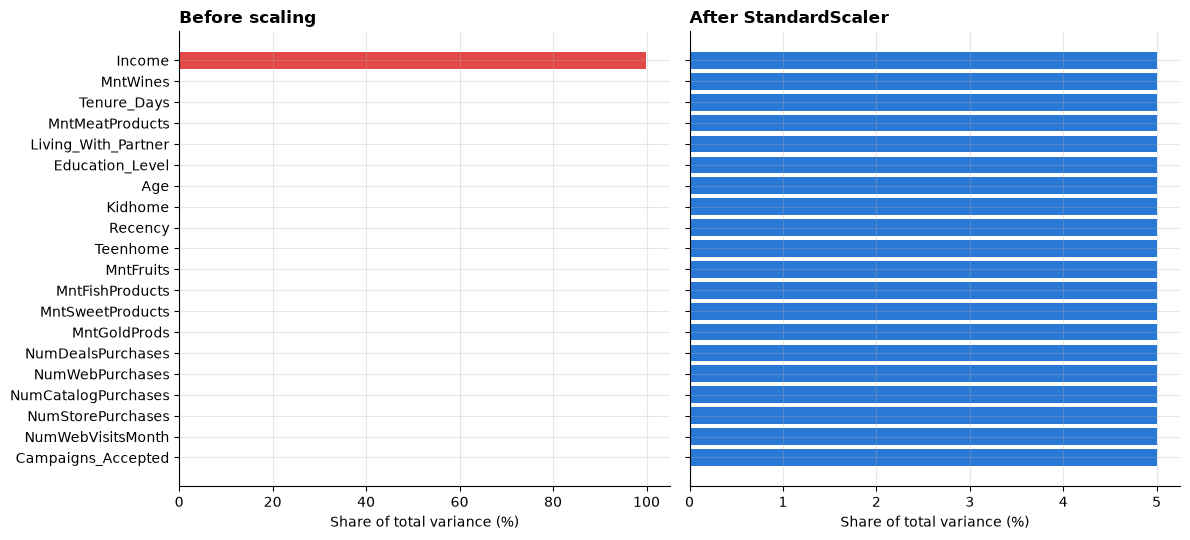

,before scaling (%),after scaling (%)
Income,99.95,5.0
MntWines,0.02,5.0
Tenure_Days,0.01,5.0
MntMeatProducts,0.01,5.0
Living_With_Partner,0.00,5.0


In [106]:
share_before = X.var(ddof=0) / X.var(ddof=0).sum() * 100
share_after = X_scaled.var(ddof=0) / X_scaled.var(ddof=0).sum() * 100
variance_share = pd.DataFrame({"before scaling (%)": share_before,
                               "after scaling (%)": share_after}).round(2)
variance_share = variance_share.sort_values("before scaling (%)", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
order = variance_share.index[::-1]
axes[0].barh(order, variance_share.loc[order, "before scaling (%)"], color=RED)
axes[0].set_title("Before scaling", loc="left", fontweight="bold")
axes[0].set_xlabel("Share of total variance (%)")
axes[1].barh(order, variance_share.loc[order, "after scaling (%)"], color=BLUE)
axes[1].set_title("After StandardScaler", loc="left", fontweight="bold")
axes[1].set_xlabel("Share of total variance (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_variance_share_scaling.png", dpi=150)
plt.show()

variance_share.head(5)

### 7.2 Extreme values after scaling

Scaling changes the units, not the shape of a distribution. Values more than 3 standard
deviations from the mean (|z| > 3) can still pull K-Means centroids, so they are counted per
feature together with each feature's skewness.

In [107]:
extreme = pd.DataFrame({
    "values with |z| > 3": (X_scaled.abs() > 3).sum(),
    "percent of customers": ((X_scaled.abs() > 3).mean() * 100).round(2),
    "skew": X.skew().round(2),
}).sort_values("values with |z| > 3", ascending=False)

customers_with_any = int((X_scaled.abs() > 3).any(axis=1).sum())
print(f"Customers with at least one |z| > 3: {customers_with_any} "
      f"({customers_with_any / len(X_scaled) * 100:.1f}%)")
extreme

Customers with at least one |z| > 3: 264 (13.0%)


,values with |z| > 3,percent of customers,skew
MntFruits,60,2.96,2.11
MntSweetProducts,54,2.67,2.11
MntFishProducts,52,2.57,1.93
MntGoldProds,42,2.07,1.85
Campaigns_Accepted,42,2.07,2.41
MntMeatProducts,34,1.68,2.05
NumDealsPurchases,29,1.43,2.45
MntWines,13,0.64,1.17
NumWebVisitsMonth,9,0.44,0.27
Income,7,0.35,0.37


### 7.3 Log transform of skewed features

13% of customers have at least one value beyond |z| > 3, concentrated in the spending columns
(skew ≈ 2). These are genuine high spenders, not errors, so removing them would discard real
customers. Instead, features with skew above 1 are transformed with log(1 + x) before scaling:
every customer is kept, the order of values is preserved, and long tails no longer pull the
K-Means centroids. The transform is reversed with exp(x) − 1 when centroids are translated back
into real units for the personas.

In [108]:
SKEW_THRESHOLD = 1.0
skewed = X.skew()
LOG_FEATURES = skewed[skewed > SKEW_THRESHOLD].index.tolist()
assert (X[LOG_FEATURES] >= 0).all().all(), "log1p needs non-negative values"

X_model = X.copy()
X_model[LOG_FEATURES] = np.log1p(X_model[LOG_FEATURES])

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_model), columns=CLUSTER_FEATURES, index=X.index)

before = (X - X.mean()) / X.std(ddof=0)
comparison = pd.DataFrame({
    "skew before": X[LOG_FEATURES].skew().round(2),
    "skew after": X_model[LOG_FEATURES].skew().round(2),
    "|z| > 3 before": (before[LOG_FEATURES].abs() > 3).sum(),
    "|z| > 3 after": (X_scaled[LOG_FEATURES].abs() > 3).sum(),
})

any_before = int((before.abs() > 3).any(axis=1).sum())
any_after = int((X_scaled.abs() > 3).any(axis=1).sum())
print(f"Log-transformed features ({len(LOG_FEATURES)}): {LOG_FEATURES}")
print(f"Customers with at least one |z| > 3: {any_before} ({any_before / len(X):.1%}) "
      f"-> {any_after} ({any_after / len(X):.1%})")
print(f"Customers kept: {len(X_scaled):,} of {len(X):,}")
comparison

Log-transformed features (10): ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'Campaigns_Accepted']
Customers with at least one |z| > 3: 264 (13.0%) -> 68 (3.4%)
Customers kept: 2,025 of 2,025


,skew before,skew after,|z| > 3 before,|z| > 3 after
MntWines,1.17,-0.56,13,0
MntFruits,2.11,0.08,60,0
MntMeatProducts,2.05,-0.09,34,0
MntFishProducts,1.93,-0.04,52,0
MntSweetProducts,2.11,0.09,54,0
MntGoldProds,1.85,-0.35,42,0
NumDealsPurchases,2.45,0.66,29,12
NumWebPurchases,1.23,-0.28,3,3
NumCatalogPurchases,1.96,0.13,4,3
Campaigns_Accepted,2.41,1.53,42,42


### 7.4 Distributions before and after the transform

Three of the most skewed spending features, shown on their original scale and after log(1 + x).

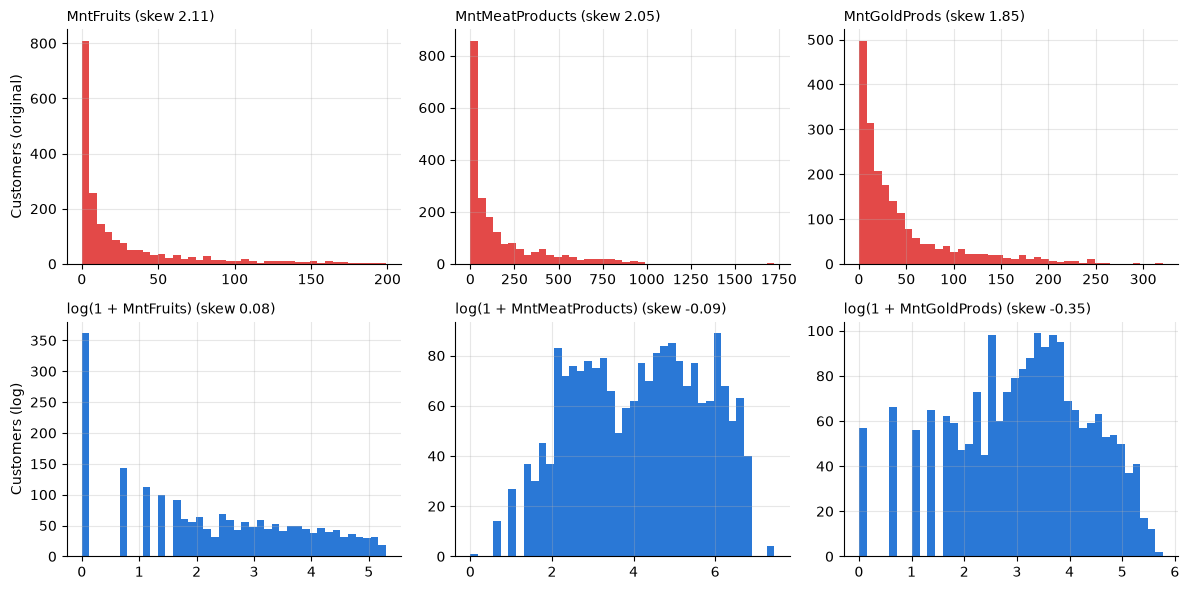

In [109]:
examples = [c for c in ["MntFruits", "MntMeatProducts", "MntGoldProds"] if c in LOG_FEATURES]
fig, axes = plt.subplots(2, len(examples), figsize=(4 * len(examples), 6))
axes = np.atleast_2d(axes)
for j, col in enumerate(examples):
    axes[0, j].hist(X[col], bins=40, color=RED)
    axes[0, j].set_title(f"{col} (skew {X[col].skew():.2f})", loc="left", fontsize=10)
    axes[1, j].hist(X_model[col], bins=40, color=BLUE)
    axes[1, j].set_title(f"log(1 + {col}) (skew {X_model[col].skew():.2f})", loc="left", fontsize=10)
axes[0, 0].set_ylabel("Customers (original)")
axes[1, 0].set_ylabel("Customers (log)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_log_transform.png", dpi=150)
plt.show()

## 8. Dimensionality reduction with PCA

With 20 dimensions, distances between customers become less informative (the curse of
dimensionality). PCA finds new axes — principal components — along which the data varies most
(Σv = λv: each eigenvector v is a direction, its eigenvalue λ is the variance along it).
Correlated features are combined, so a few components can carry most of the information.

Two targets are checked:

- **95% variance rule:** the number of components needed to keep 95% of the variance.
- **Project requirement:** how much variance 2 and 3 components keep.

In [110]:
from sklearn.decomposition import PCA

RANDOM_STATE = 42
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)

explained = pd.DataFrame({
    "component": [f"PC{i}" for i in range(1, len(CLUSTER_FEATURES) + 1)],
    "variance (%)": pca_full.explained_variance_ratio_ * 100,
    "cumulative (%)": np.cumsum(pca_full.explained_variance_ratio_) * 100,
}).round(2)

N_95 = int(np.searchsorted(explained["cumulative (%)"].to_numpy(), 95) + 1)
VAR_2D = explained.loc[1, "cumulative (%)"]
VAR_3D = explained.loc[2, "cumulative (%)"]

print(f"Components needed for 95% of the variance: {N_95} of {len(CLUSTER_FEATURES)}")
print(f"Variance kept by 2 components: {VAR_2D:.2f}%")
print(f"Variance kept by 3 components: {VAR_3D:.2f}%")
explained.head(N_95)

Components needed for 95% of the variance: 15 of 20
Variance kept by 2 components: 47.61%
Variance kept by 3 components: 56.15%


,component,variance (%),cumulative (%)
0,PC1,37.04,37.04
1,PC2,10.56,47.61
2,PC3,8.54,56.15
3,PC4,6.02,62.17
4,PC5,5.09,67.26
5,PC6,4.91,72.17
6,PC7,4.28,76.45
7,PC8,3.95,80.40
8,PC9,2.98,83.38
9,PC10,2.76,86.14


### 8.1 Explained variance

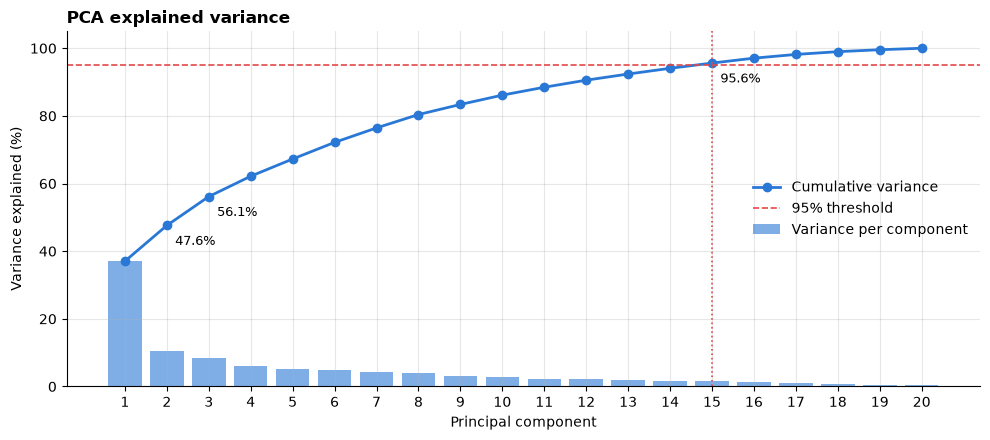

In [111]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(1, len(explained) + 1)
ax.bar(x, explained["variance (%)"], color=BLUE, alpha=0.6, label="Variance per component")
ax.plot(x, explained["cumulative (%)"], color=BLUE, marker="o", linewidth=2, label="Cumulative variance")
ax.axhline(95, color=RED, linestyle="--", linewidth=1.2, label="95% threshold")
ax.axvline(N_95, color=RED, linestyle=":", linewidth=1.2)
for k, var in [(2, VAR_2D), (3, VAR_3D), (N_95, explained.loc[N_95 - 1, "cumulative (%)"])]:
    ax.annotate(f"{var:.1f}%", (k, var), textcoords="offset points", xytext=(6, -14), fontsize=9)
ax.set_xticks(x)
ax.set_xlabel("Principal component")
ax.set_ylabel("Variance explained (%)")
ax.set_ylim(0, 105)
ax.set_title("PCA explained variance", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="center right")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_pca_explained_variance.png", dpi=150)
plt.show()

### 8.2 What the first three components mean

Loadings are the weights of each original feature in a component. Large positive or negative
values show which features define that axis.

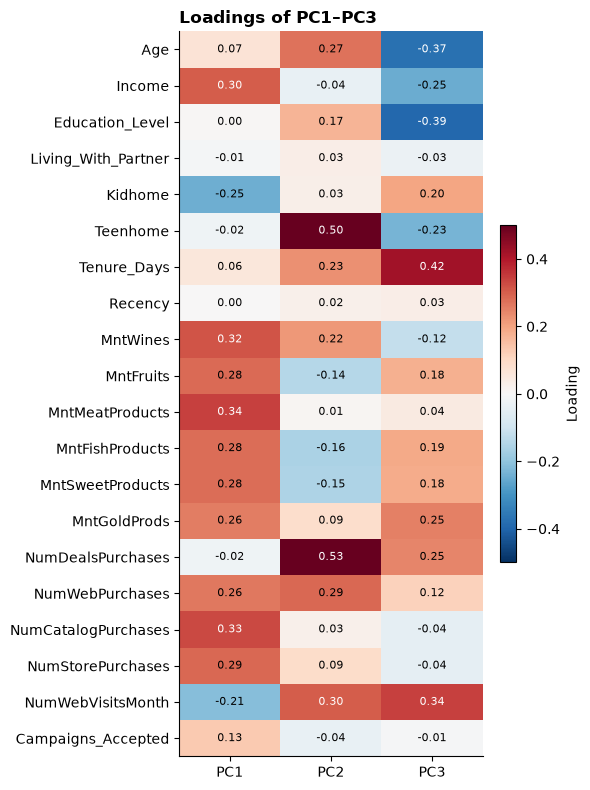

,PC1,PC2,PC3
#1,MntMeatProducts (+0.34),NumDealsPurchases (+0.53),Tenure_Days (+0.42)
#2,NumCatalogPurchases (+0.33),Teenhome (+0.50),Education_Level (-0.39)
#3,MntWines (+0.32),NumWebVisitsMonth (+0.30),Age (-0.37)
#4,Income (+0.30),NumWebPurchases (+0.29),NumWebVisitsMonth (+0.34)
#5,NumStorePurchases (+0.29),Age (+0.27),MntGoldProds (+0.25)


In [112]:
loadings = pd.DataFrame(pca_full.components_[:3].T, index=CLUSTER_FEATURES,
                        columns=["PC1", "PC2", "PC3"])

fig, ax = plt.subplots(figsize=(6, 8))
im = ax.imshow(loadings, cmap="RdBu_r", vmin=-0.5, vmax=0.5, aspect="auto")
ax.set_xticks(range(3), loadings.columns)
ax.set_yticks(range(len(loadings)), loadings.index)
for i in range(len(loadings)):
    for j in range(3):
        v = loadings.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.3 else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.05, label="Loading")
ax.set_title("Loadings of PC1–PC3", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_pca_loadings.png", dpi=150)
plt.show()

top_features = {}
for pc in loadings.columns:
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(5)
    top_features[pc] = [f"{feature} ({weight:+.2f})" for feature, weight in top.items()]
pd.DataFrame(top_features, index=[f"#{i}" for i in range(1, 6)])

### 8.3 Customers projected onto the first components

`X_pca3` (3 components) is the reduced space required by the project; `X_pca95` keeps 95% of the
variance and is used in the next section to check that the chosen number of clusters holds in
both spaces.

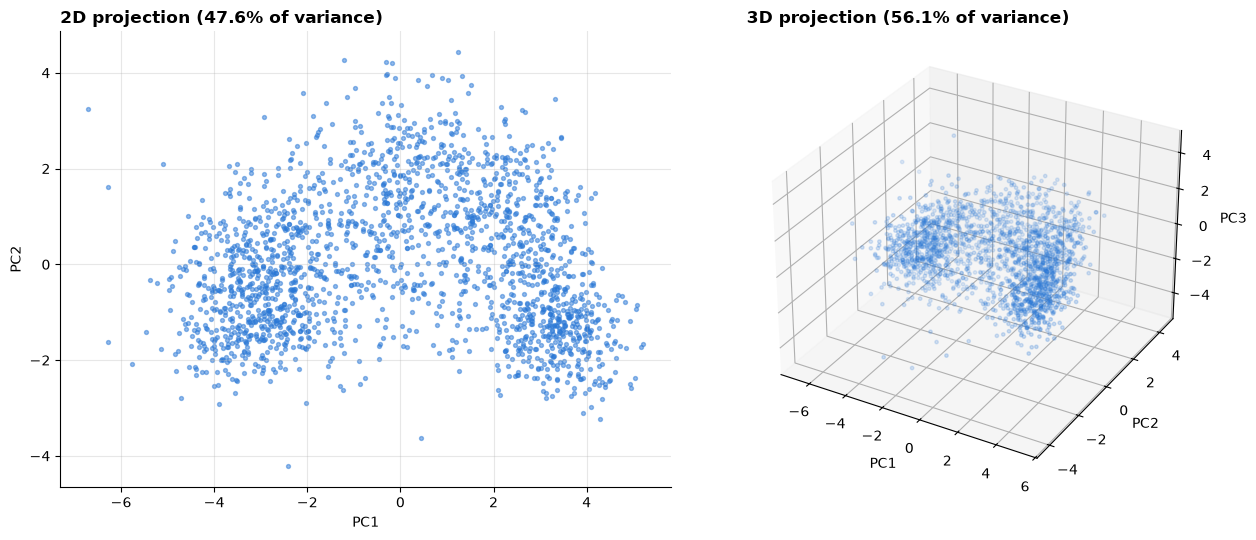

X_pca3 : (2025, 3)
X_pca95: (2025, 15)


In [113]:
X_pca3 = pd.DataFrame(PCA(n_components=3, random_state=RANDOM_STATE).fit_transform(X_scaled),
                      columns=["PC1", "PC2", "PC3"], index=X_scaled.index)
X_pca95 = PCA(n_components=N_95, random_state=RANDOM_STATE).fit_transform(X_scaled)

fig = plt.figure(figsize=(13, 5.5))
ax2d = fig.add_subplot(1, 2, 1)
ax2d.scatter(X_pca3["PC1"], X_pca3["PC2"], s=8, alpha=0.5, color=BLUE)
ax2d.set_xlabel("PC1")
ax2d.set_ylabel("PC2")
ax2d.set_title(f"2D projection ({VAR_2D:.1f}% of variance)", loc="left", fontweight="bold")

ax3d = fig.add_subplot(1, 2, 2, projection="3d")
ax3d.scatter(X_pca3["PC1"], X_pca3["PC2"], X_pca3["PC3"], s=6, alpha=0.5, color=BLUE)
ax3d.set_xlabel("PC1")
ax3d.set_ylabel("PC2")
ax3d.set_zlabel("PC3")
ax3d.set_title(f"3D projection ({VAR_3D:.1f}% of variance)", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_pca_projection.png", dpi=150)
plt.show()

print("X_pca3 :", X_pca3.shape)
print("X_pca95:", X_pca95.shape)

## 9. Choosing the number of clusters (K)

K-Means does not choose K itself; it creates exactly as many clusters as requested. Two
independent tests are used:

- **Elbow method:** WCSS = Σ‖x − μₖ‖² for K = 1…10. WCSS always falls as K grows; the elbow is
  where adding a cluster stops giving a large reduction. The **Kneedle algorithm** locates it
  mathematically instead of by eye.
- **Silhouette score:** s(i) = (b − a) / max(a, b), where *a* is a customer's mean distance to its
  own cluster and *b* to the nearest other cluster. Values close to +1 mean well-separated clusters.

Both are computed in the 3-component space used for clustering and, as a robustness check, in the
15-component space that keeps 95% of the variance.

In [114]:
from kneed import KneeLocator
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_RANGE = range(1, 11)


def evaluate_k(data):
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(data)
        sil = silhouette_score(data, km.labels_) if k > 1 else np.nan
        rows.append({"K": k, "WCSS": km.inertia_, "silhouette": sil})
    return pd.DataFrame(rows).set_index("K")


scores_3d = evaluate_k(X_pca3)
scores_95 = evaluate_k(X_pca95)


def elbow_k(scores):
    return KneeLocator(list(scores.index), scores["WCSS"].tolist(),
                       curve="convex", direction="decreasing").elbow


summary_k = pd.DataFrame({
    "Kneedle elbow K": [elbow_k(scores_3d), elbow_k(scores_95)],
    "best silhouette K": [scores_3d["silhouette"].idxmax(), scores_95["silhouette"].idxmax()],
    "best silhouette": [scores_3d["silhouette"].max(), scores_95["silhouette"].max()],
}, index=["3 components", f"{N_95} components (95%)"]).round(3)
summary_k

,Kneedle elbow K,best silhouette K,best silhouette
3 components,3,2,0.444
15 components (95%),3,2,0.265


### 9.1 Scores for every K

In [115]:
pd.concat({"3 components": scores_3d, f"{N_95} components (95%)": scores_95}, axis=1).round(3)

3 components            15 components (95%)           
           WCSS silhouette                WCSS silhouette
K                                                        
1     22740.574        NaN           38727.801        NaN
2     10904.677      0.444           26882.885      0.265
3      7734.825      0.387           23668.993      0.195
4      6474.344      0.337           22348.670      0.144
5      5572.057      0.311           21203.151      0.120
6      4952.303      0.309           20467.451      0.117
7      4483.340      0.306           19756.234      0.113
8      4164.184      0.304           19291.082      0.112
9      3858.999      0.278           18866.712      0.097
10     3598.190      0.266           18513.576      0.101

### 9.2 Elbow and silhouette curves

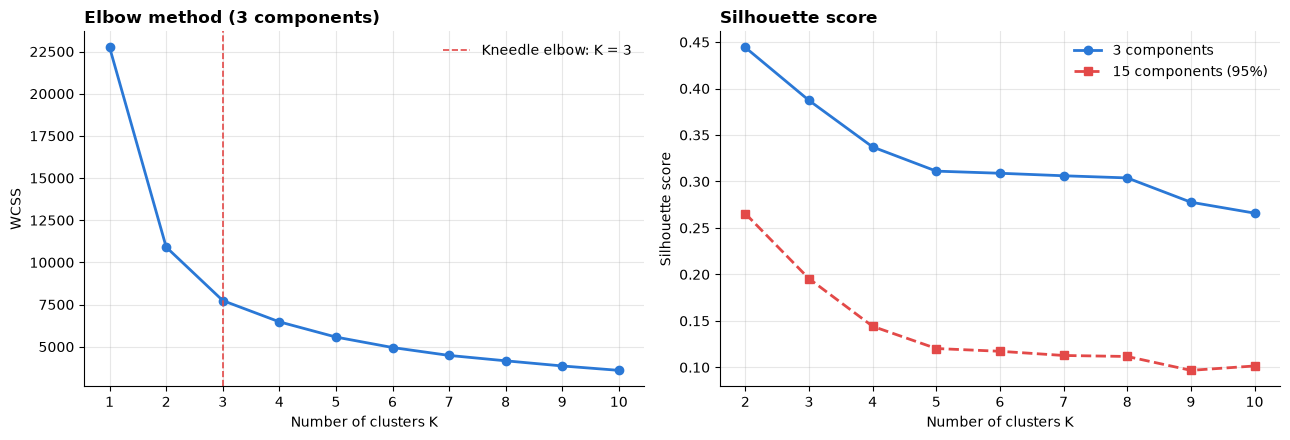

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
elbow_3d = elbow_k(scores_3d)

axes[0].plot(scores_3d.index, scores_3d["WCSS"], marker="o", color=BLUE, linewidth=2)
if elbow_3d is not None:
    axes[0].axvline(elbow_3d, color=RED, linestyle="--", linewidth=1.2,
                    label=f"Kneedle elbow: K = {elbow_3d}")
    axes[0].legend(frameon=False)
axes[0].set_xticks(list(K_RANGE))
axes[0].set_xlabel("Number of clusters K")
axes[0].set_ylabel("WCSS")
axes[0].set_title("Elbow method (3 components)", loc="left", fontweight="bold")

sil_3d = scores_3d["silhouette"].dropna()
sil_95 = scores_95["silhouette"].dropna()
axes[1].plot(sil_3d.index, sil_3d, marker="o", color=BLUE, linewidth=2, label="3 components")
axes[1].plot(sil_95.index, sil_95, marker="s", color=RED, linewidth=2, linestyle="--",
             label=f"{N_95} components (95%)")
axes[1].set_xticks(list(sil_3d.index))
axes[1].set_xlabel("Number of clusters K")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score", loc="left", fontweight="bold")
axes[1].legend(frameon=False)

fig.tight_layout()
fig.savefig(FIG_DIR / "06_elbow_silhouette.png", dpi=150)
plt.show()